# 2. Player modelling (Objective O1)

Two questions, both answered on a cohort of 300 real Chess.com players, 60 in each of five rating bands.

1. Can a player's **strength** be recognised from how they play, with the rating hidden?
2. Can a player's **tactical weaknesses** be measured from their games?

**Sources:** `eval/research/rating_classification.json` (`scripts/research/classify_rating_band.py`) and
`eval/research/cohort_evaluation_puzzlenet.json` (`scripts/research/evaluate_weakness_models.py`). The cohort itself
is private; only these aggregate results are published.

In [1]:
import pandas as pd
from nb_utils import ROOT, figures, load

pd.set_option('display.max_columns', None, 'display.width', 120)

## Strength: rating band from 18 features of play

Stratified five-fold cross-validation over players, repeated ten times, with a permutation test of 500 shuffles.

In [2]:
rating = load('eval/research/rating_classification.json')
rows = {name: {'accuracy': m['accuracy_mean'], 'sd': m['accuracy_sd'], 'macro F1': m['macro_f1_mean'],
               'within one band': m['within_one_band'], 'permutation p': m['permutation_p']}
        for name, m in rating['models'].items()}
pd.DataFrame(rows).T.round(3)

,accuracy,sd,macro F1,within one band,permutation p
Logistic regression,0.591,0.018,0.588,0.931,0.002
Random forest,0.574,0.019,0.570,0.938,0.002


In [3]:
matrix = pd.DataFrame(rating['models']['Logistic regression']['confusion_matrix'],
                      index=rating['classes'], columns=rating['classes'])
recall = pd.Series({band: matrix.loc[band, band] / matrix.loc[band].sum() for band in matrix.index}, name='correct')
print(rating['rating_regression'])
recall.round(2).to_frame().T

{'mae': 205.6, 'baseline_mae': 490.2, 'pearson_r': 0.8945}


,<1000,1000–1399,1400–1799,1800–2199,2200+
correct,0.85,0.52,0.45,0.5,0.75


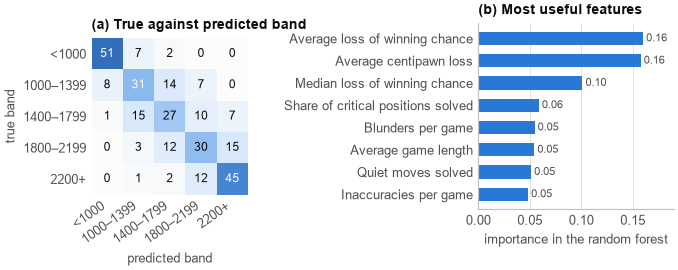

In [4]:
figures.strength()

### Observations

- Logistic regression places 59.1% of unseen players in the correct band, against 20% by chance, and 93% within one band.
- No shuffle of the permutation test reached this accuracy ($p = 0.002$, the smallest value 500 shuffles can give).
- Errors fall mostly into a neighbouring band. The weakest and strongest bands are recognised best; the middle ones overlap.
- The most useful features measure how accurately someone plays: loss of winning chance and centipawn loss per move.
- Predicting the rating as a number gives a mean error of 206 points, against 490 for the average, with $r = 0.89$.

## Weaknesses: predicting future misses

Each player's oldest two thirds of games are the history and the newest third the test. The baseline is the category base rate, which knows only how hard each category is for everyone.

In [5]:
cohort = load('eval/research/cohort_evaluation_puzzlenet.json')
print('test positions:', cohort['test_opportunities'])
rows = {name: {'log loss': m['log_loss'], 'AUC': m['auc'], 'vs category base': m['logloss_minus_category_base'],
               'CI low': m['ci95'][0], 'CI high': m['ci95'][1]}
        for name, m in cohort['models'].items()}
pd.DataFrame(rows).T.round(4)

test positions: 9074


,log loss,AUC,vs category base,CI low,CI high
Global base rate,0.6402,0.4897,0.0086,0.0054,0.0118
Category base rate,0.6316,0.5766,0.0000,0.0000,0.0000
Player base rate,0.6391,0.5548,0.0075,0.0018,0.0130
Rule-based scorer,0.6401,0.5003,0.0085,0.0055,0.0116
RF (synthetic-trained),0.6400,0.4997,0.0084,0.0052,0.0116
"EB, shrink to player rate",0.6484,0.5583,0.0167,0.0098,0.0238
"EB, shrink to population norms",0.6288,0.5952,-0.0028,-0.0072,0.0015
RF (real-data),0.6266,0.5964,-0.0050,-0.0083,-0.0018


In [6]:
pd.DataFrame(cohort['reliability']).round(3)

,category,players,split_half_r,spearman_brown
0,Fork,57,-0.126,-0.288
1,Pin,22,0.067,0.126
2,Hanging Piece,151,0.039,0.075
3,Quiet Move,241,0.076,0.141
4,Mating Pattern,32,0.167,0.286
5,Endgame,221,-0.082,-0.179


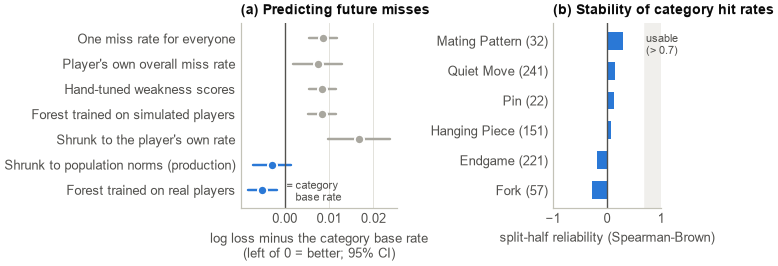

In [7]:
figures.weakness()

### Observations

- The hand-tuned weakness scores are no better than chance (AUC 0.50).
- Only two models beat the category base rate: the production profile, by 0.003 in log loss with an interval that
  includes zero, and a random forest trained on real players, by 0.005.
- The split-half reliability of hit rates per category lies between −0.29 and 0.29, far below the usual 0.7.
- **Conclusion:** a few dozen games hold almost no stable personal signal about single motifs, so the selector learns
  weaknesses from puzzle attempts and treats the game profile only as a weak starting point.